# Caribbean Poker - Simulation et Analyse

Ce notebook contient des fonctions pour simuler et analyser le jeu de Caribbean Poker.


In [1]:
import random
from itertools import combinations


## 1. Création du jeu de cartes


In [2]:
def create_deck():
    """Créer un jeu de 52 cartes standard."""
    ranks = ['2', '3', '4', '5', '6', '7', '8', '9', 'T', 'J', 'Q', 'K', 'A']
    suits = ['h', 'd', 'c', 's']  # hearts, diamonds, clubs, spades
    return [r + s for r in ranks for s in suits]

# Test de création du deck
deck = create_deck()
print(f"Deck créé avec {len(deck)} cartes")
print(f"Premières cartes: {deck[:10]}")


Deck créé avec 52 cartes
Premières cartes: ['2h', '2d', '2c', '2s', '3h', '3d', '3c', '3s', '4h', '4d']


## 2. Simulation d'une distribution


In [3]:
def simulate_deal(num_players, player_hand_size=5):
    """
    Simule un deal de Caribbean Poker :
    - 'num_players' joueurs reçoivent chacun 'player_hand_size' cartes.
    - Le dealer reçoit une carte visible (upcard).

    Args:
        num_players (int): Nombre de joueurs.
        player_hand_size (int): Taille de la main pour chaque joueur (par défaut 5).

    Returns:
        hands (list of lists): Mains des joueurs.
        dealer_upcard (str): Carte visible du dealer.
        remaining_deck (list): Cartes restantes après la distribution.
    """
    deck = create_deck()
    random.shuffle(deck)
    
    # Distribution des mains des joueurs
    hands = [[deck.pop() for _ in range(player_hand_size)] for _ in range(num_players)]
    
    # Carte visible du dealer
    dealer_upcard = deck.pop()
    
    # Cartes restantes
    remaining_deck = deck.copy()
    
    return hands, dealer_upcard, remaining_deck

# Test de simulation
hands, upcard, remaining = simulate_deal(3)
print(f"Mains des joueurs: {hands}")
print(f"Carte visible du dealer: {upcard}")
print(f"Cartes restantes: {len(remaining)} cartes")


Mains des joueurs: [['Js', '9h', '8h', '7d', '5h'], ['6h', '3d', '3h', '8s', 'Kd'], ['Qs', 'Tc', '6c', '7h', 'Th']]
Carte visible du dealer: Jc
Cartes restantes: 36 cartes


## 3. Génération de mains possibles


In [4]:
def generate_hands(cards, hand_size, required_cards=None):
    """
    Génère toutes les combinaisons possibles de 'hand_size' cartes
    à partir d'une liste de cartes donnée en incluant les cartes requises.

    Args:
        cards (list): Liste des cartes disponibles pour compléter.
        hand_size (int): Taille totale de chaque main.
        required_cards (list or tuple, optional): Cartes devant être incluses dans chaque main.

    Returns:
        list of tuples: Mains possibles contenant les cartes requises.

    Raises:
        ValueError: Si hand_size < len(required_cards).
    """
    required = list(required_cards) if required_cards else []
    k = hand_size - len(required)
    
    if k < 0:
        raise ValueError("hand_size est plus petit que le nombre de cartes requises")

    # Générer les combinaisons des cartes disponibles
    return [tuple(required + list(combo)) for combo in combinations(cards, k)]

# Test de génération de mains
test_cards = ['Ah', 'Kh', 'Qh', 'Jh', 'Th']
possible_hands = generate_hands(test_cards, 3, required_cards=['Ah'])
print(f"Mains possibles avec Ah requis: {possible_hands}")
print(f"Nombre total de mains: {len(possible_hands)}")


Mains possibles avec Ah requis: [('Ah', 'Ah', 'Kh'), ('Ah', 'Ah', 'Qh'), ('Ah', 'Ah', 'Jh'), ('Ah', 'Ah', 'Th'), ('Ah', 'Kh', 'Qh'), ('Ah', 'Kh', 'Jh'), ('Ah', 'Kh', 'Th'), ('Ah', 'Qh', 'Jh'), ('Ah', 'Qh', 'Th'), ('Ah', 'Jh', 'Th')]
Nombre total de mains: 10


## 4. Analyse complète du Caribbean Poker sans proba


In [5]:
def analyze_caribbean_dealer(num_players, player_hand_size=5, dealer_hand_size=5):
    """
    Fonction wrapper qui :
    1. Simule un deal pour les joueurs et le dealer.
    2. Génère toutes les mains potentielles du dealer incluant son upcard.

    Args:
        num_players (int): Nombre de joueurs.
        player_hand_size (int): Taille de main de chaque joueur.
        dealer_hand_size (int): Taille de main complète du dealer (par défaut 5).

    Returns:
        tuple:
            - hands (list of lists): Mains des joueurs.
            - dealer_upcard (str): Carte visible du dealer.
            - possible_dealer_hands (list of tuples): Toutes les mains possibles du dealer.
            - remaining_deck (list): Cartes restantes.
    """
    # Simuler la distribution
    hands, dealer_upcard, remaining_deck = simulate_deal(num_players, player_hand_size)
    
    # Générer toutes les mains potentielles du dealer
    possible_dealer_hands = generate_hands(
        remaining_deck,
        dealer_hand_size,
        required_cards=[dealer_upcard]
    )
    
    return hands, dealer_upcard, possible_dealer_hands, remaining_deck

# Exemple d'utilisation complète
print("=== Simulation Caribbean Poker ===")
num_players = 3
hands, upcard, dealer_hands, remaining = analyze_caribbean_dealer(num_players)

print(f"\nJoueurs ({num_players}):")
for i, hand in enumerate(hands, 1):
    print(f"  Joueur {i}: {hand}")

print(f"\nDealer upcard: {upcard}")
print(f"Nombre de mains potentielles du dealer: {len(dealer_hands)}")
print(f"Exemples de mains du dealer: {dealer_hands[:5]}")
print(f"Cartes restantes: {len(remaining)} cartes")


=== Simulation Caribbean Poker ===

Joueurs (3):
  Joueur 1: ['Ah', 'Qs', 'Kc', '3c', '7s']
  Joueur 2: ['8s', '9h', '9c', '6c', '4c']
  Joueur 3: ['6h', '2d', 'Jd', '4d', '5s']

Dealer upcard: As
Nombre de mains potentielles du dealer: 58905
Exemples de mains du dealer: [('As', '5d', 'Kh', '8h', '9d'), ('As', '5d', 'Kh', '8h', '3s'), ('As', '5d', 'Kh', '8h', 'Qh'), ('As', '5d', 'Kh', '8h', '6s'), ('As', '5d', 'Kh', '8h', 'Ad')]
Cartes restantes: 36 cartes


## 5. séparer la main du croupier en deux subset les mains ou il ne se qualifie pas et celle qui se qualifie avec As et Roi minimum et donner la proba qu'il ne se qualifie pas

In [6]:
from collections import Counter

# Fonctions pour évaluer les mains de poker
RANK_ORDER = "23456789TJQKA"
VALUE_MAP = {r: i for i, r in enumerate(RANK_ORDER, start=2)}

def _sorted_values(cards):
    """Return card ranks sorted descending according to VALUE_MAP."""
    return sorted((VALUE_MAP[c[0]] for c in cards), reverse=True)

def _is_flush(cards):
    suits = [c[1] for c in cards]
    return len(set(suits)) == 1

def _is_straight(values):
    # Handle wheel straight (A-2-3-4-5)
    if values == [14, 5, 4, 3, 2]:
        return True, 5  # low straight, high card = 5
    for i in range(4):
        if values[i] - values[i + 1] != 1:
            return False, None
    return True, values[0]

def hand_rank(cards):
    """Return a tuple (category, tiebreakers list) for a 5-card hand."""
    values = _sorted_values(cards)
    counts = Counter(values)
    groups = sorted(((cnt, val) for val, cnt in counts.items()), reverse=True)
    flush = _is_flush(cards)
    straight, high_straight = _is_straight(values)

    # Straight / Flush / Straight Flush / Royal Flush
    if straight and flush:
        if high_straight == 14:  # 10-A straight flush
            rank_cat = 9  # Royal Flush
        else:
            rank_cat = 8  # Straight Flush
        return (rank_cat, [high_straight])

    # Four of a Kind
    if groups[0][0] == 4:
        quad_val = groups[0][1]
        kicker = groups[1][1]
        return (7, [quad_val, kicker])

    # Full House
    if groups[0][0] == 3 and groups[1][0] == 2:
        return (6, [groups[0][1], groups[1][1]])

    # Flush
    if flush:
        return (5, values)

    # Straight
    if straight:
        return (4, [high_straight])

    # Three of a Kind
    if groups[0][0] == 3:
        remaining = sorted((v for v in values if v != groups[0][1]), reverse=True)
        return (3, [groups[0][1]] + remaining)

    # Two Pair
    if groups[0][0] == 2 and groups[1][0] == 2:
        pair_vals = sorted((groups[0][1], groups[1][1]), reverse=True)
        kicker = groups[2][1]
        return (2, pair_vals + [kicker])

    # One Pair
    if groups[0][0] == 2:
        pair_val = groups[0][1]
        kickers = sorted((v for v in values if v != pair_val), reverse=True)
        return (1, [pair_val] + kickers)

    # High Card
    return (0, values)

def compare_hands(hand1, hand2):
    """Compare deux mains et renvoie 1 si hand1 gagne, -1 si hand2 gagne, 0 sinon."""
    rank1 = hand_rank(hand1)
    rank2 = hand_rank(hand2)
    if rank1 > rank2:
        return 1
    if rank1 < rank2:
        return -1
    return 0


In [7]:
def dealer_qualifies(hand):
    """
    Vérifie si le dealer se qualifie au Caribbean Poker.
    Le dealer se qualifie avec au minimum As-Roi.
    
    Args:
        hand (list): Main de 5 cartes du dealer
        
    Returns:
        bool: True si le dealer se qualifie, False sinon
    """
    values = _sorted_values(hand)
    
    # Vérifier les paires ou mieux (toujours qualifié)
    counts = Counter(values)
    max_count = max(counts.values())
    if max_count >= 2:
        return True
    
    # Pour les cartes hautes, vérifier As-Roi minimum
    # As = 14, Roi = 13
    if 14 in values and 13 in values:
        return True
    
    return False

# Test de la fonction de qualification
test_hands = [
    ["Ah", "Kh", "7c", "3d", "2s"],  # As-Roi (se qualifie)
    ["Ah", "Qh", "7c", "3d", "2s"],  # As-Dame (ne se qualifie pas)
    ["Kh", "Qh", "Jc", "Td", "9s"],  # Roi haut (ne se qualifie pas)
    ["8h", "8c", "7d", "3s", "2h"],  # Paire de 8 (se qualifie)
]

print("Tests de qualification du dealer:")
for i, hand in enumerate(test_hands, 1):
    qualifie = dealer_qualifies(hand)
    print(f"Main {i} {hand}: {'SE QUALIFIE' if qualifie else 'NE SE QUALIFIE PAS'}")


Tests de qualification du dealer:
Main 1 ['Ah', 'Kh', '7c', '3d', '2s']: SE QUALIFIE
Main 2 ['Ah', 'Qh', '7c', '3d', '2s']: NE SE QUALIFIE PAS
Main 3 ['Kh', 'Qh', 'Jc', 'Td', '9s']: NE SE QUALIFIE PAS
Main 4 ['8h', '8c', '7d', '3s', '2h']: SE QUALIFIE


In [8]:
def analyze_hand_combinations(hand_combinations):
    """
    Analyse une liste de combinaisons de cartes pour déterminer 
    lesquelles se qualifient et la probabilité de non-qualification.
    
    Args:
        hand_combinations (list): Liste de mains de 5 cartes à analyser
        
    Returns:
        dict: Analyse complète des combinaisons
    """
    qualified_hands = []
    non_qualified_hands = []
    
    # Analyser chaque combinaison
    for hand in hand_combinations:
        if dealer_qualifies(hand):
            qualified_hands.append(hand)
        else:
            non_qualified_hands.append(hand)
    
    total_hands = len(hand_combinations)
    
    results = {
        'total_hands': total_hands,
        'qualified_hands': qualified_hands,
        'non_qualified_hands': non_qualified_hands,
        'num_qualified': len(qualified_hands),
        'num_non_qualified': len(non_qualified_hands),
        'qualification_rate': len(qualified_hands) / total_hands if total_hands > 0 else 0,
        'non_qualification_rate': len(non_qualified_hands) / total_hands if total_hands > 0 else 0
    }
    
    return results

# Test avec des combinaisons d'exemple
test_combinations = [
    ["Ah", "Kh", "Qc", "Jd", "Ts"],  # As-Roi (se qualifie)
    ["Ah", "Qh", "Jc", "Td", "9s"],  # As-Dame (ne se qualifie pas)
    ["Kh", "Qh", "Jc", "Td", "9s"],  # Roi haut (ne se qualifie pas)
    ["8h", "8c", "7d", "3s", "2h"],  # Paire de 8 (se qualifie)
    ["Ah", "Kh", "7c", "3d", "2s"],  # As-Roi (se qualifie)
    ["Qh", "Jh", "Tc", "9d", "8s"],  # Dame haut (ne se qualifie pas)
    ["Ah", "Ad", "7c", "3d", "2s"],  # Paire d'As (se qualifie)
    ["Kh", "Qh", "7c", "3d", "2s"],  # Roi-Dame (ne se qualifie pas)
]

print("=== Analyse de combinaisons spécifiques ===")
results = analyze_hand_combinations(test_combinations)

print(f"\\nRésultats sur {results['total_hands']} combinaisons analysées:")
print(f"Mains qualifiées: {results['num_qualified']} ({results['qualification_rate']:.1%})")
print(f"Mains non qualifiées: {results['num_non_qualified']} ({results['non_qualification_rate']:.1%})")
print(f"\\nProbabilité de NON-qualification: {results['non_qualification_rate']:.1%}")

print(f"\\n=== MAINS QUALIFIÉES ===")
for i, hand in enumerate(results['qualified_hands'], 1):
    print(f"  {i}. {hand}")

print(f"\\n=== MAINS NON QUALIFIÉES ===")
for i, hand in enumerate(results['non_qualified_hands'], 1):
    print(f"  {i}. {hand}")

# Exemple avec des mains générées automatiquement
print("\\n" + "="*50)
print("=== Test avec mains générées automatiquement ===")

# Générer quelques mains possibles du dealer avec une carte visible
hands, upcard, dealer_possible_hands, remaining = analyze_caribbean_dealer(num_players=3)
sample_hands = dealer_possible_hands[:20]  # Prendre 20 mains d'exemple

auto_results = analyze_hand_combinations(sample_hands)
print(f"\\nCarte visible du dealer: {upcard}")
print(f"Échantillon de {auto_results['total_hands']} mains possibles:")
print(f"Probabilité de NON-qualification: {auto_results['non_qualification_rate']:.1%}")
print(f"\\nPremières mains qualifiées: {auto_results['qualified_hands'][:3]}")
print(f"Premières mains non qualifiées: {auto_results['non_qualified_hands'][:3]}")


=== Analyse de combinaisons spécifiques ===
\nRésultats sur 8 combinaisons analysées:
Mains qualifiées: 4 (50.0%)
Mains non qualifiées: 4 (50.0%)
\nProbabilité de NON-qualification: 50.0%
\n=== MAINS QUALIFIÉES ===
  1. ['Ah', 'Kh', 'Qc', 'Jd', 'Ts']
  2. ['8h', '8c', '7d', '3s', '2h']
  3. ['Ah', 'Kh', '7c', '3d', '2s']
  4. ['Ah', 'Ad', '7c', '3d', '2s']
\n=== MAINS NON QUALIFIÉES ===
  1. ['Ah', 'Qh', 'Jc', 'Td', '9s']
  2. ['Kh', 'Qh', 'Jc', 'Td', '9s']
  3. ['Qh', 'Jh', 'Tc', '9d', '8s']
  4. ['Kh', 'Qh', '7c', '3d', '2s']
\n==================================================
=== Test avec mains générées automatiquement ===
\nCarte visible du dealer: 6s
Échantillon de 20 mains possibles:
Probabilité de NON-qualification: 60.0%
\nPremières mains qualifiées: [('6s', 'Kd', 'Qd', '2h', '2s'), ('6s', 'Kd', 'Qd', '2h', 'As'), ('6s', 'Kd', 'Qd', '2h', 'Ac')]
Premières mains non qualifiées: [('6s', 'Kd', 'Qd', '2h', '9d'), ('6s', 'Kd', 'Qd', '2h', '5d'), ('6s', 'Kd', 'Qd', '2h', '4s')]


## 6. pour les mains qui se qualifient calculer la proba que la main du joueur gagne fasse egalite ou perde

In [9]:
def analyze_player_vs_dealer(player_hand, dealer_hands):
    """
    Analyse les probabilités de victoire/égalité/défaite d'un joueur 
    contre une liste de mains possibles du dealer.
    
    Args:
        player_hand (list): Main de 5 cartes du joueur
        dealer_hands (list): Liste des mains possibles du dealer
        
    Returns:
        dict: Analyse complète avec probabilités et listes de mains
    """
    player_wins = []
    ties = []
    player_loses = []
    
    # Comparer la main du joueur avec chaque main possible du dealer
    for dealer_hand in dealer_hands:
        result = compare_hands(player_hand, dealer_hand)
        
        if result == 1:  # Joueur gagne
            player_wins.append(dealer_hand)
        elif result == 0:  # Égalité
            ties.append(dealer_hand)
        else:  # result == -1, Joueur perd
            player_loses.append(dealer_hand)
    
    total_hands = len(dealer_hands)
    
    results = {
        'player_hand': player_hand,
        'total_dealer_hands': total_hands,
        'player_wins': player_wins,
        'ties': ties,
        'player_loses': player_loses,
        'num_wins': len(player_wins),
        'num_ties': len(ties),
        'num_losses': len(player_loses),
        'win_rate': len(player_wins) / total_hands if total_hands > 0 else 0,
        'tie_rate': len(ties) / total_hands if total_hands > 0 else 0,
        'loss_rate': len(player_loses) / total_hands if total_hands > 0 else 0
    }
    
    return results

def print_player_analysis(results):
    """Affiche les résultats de l'analyse joueur vs dealer de façon lisible."""
    print(f"=== ANALYSE: Main du joueur vs {results['total_dealer_hands']} mains du dealer ===")
    print(f"Main du joueur: {results['player_hand']}")
    print(f"\n📊 PROBABILITÉS:")
    print(f"  🏆 Victoires: {results['num_wins']} ({results['win_rate']:.1%})")
    print(f"  🤝 Égalités:  {results['num_ties']} ({results['tie_rate']:.1%})")
    print(f"  💀 Défaites:  {results['num_losses']} ({results['loss_rate']:.1%})")
    
    print(f"\n🏆 MAINS DU DEALER BATTUES (premières 5):")
    for i, hand in enumerate(results['player_wins'][:5], 1):
        print(f"  {i}. {hand}")
    
    if results['ties']:
        print(f"\n🤝 MAINS DU DEALER ÉGALES (premières 5):")
        for i, hand in enumerate(results['ties'][:5], 1):
            print(f"  {i}. {hand}")
    
    print(f"\n💀 MAINS DU DEALER SUPÉRIEURES (premières 5):")
    for i, hand in enumerate(results['player_loses'][:5], 1):
        print(f"  {i}. {hand}")

# Test avec différentes mains de joueur
test_player_hands = [
    ["As", "Ah", "Kd", "Kc", "Qs"],  # Deux paires As-Roi
    ["Ts", "Jh", "Qd", "Kc", "As"],  # Suite 10-As
    ["2s", "3h", "7d", "9c", "Js"],  # Valet haut
]

# Créer une liste complète de mains du dealer couvrant tous les scénarios
def create_comprehensive_dealer_hands():
    """
    Crée une liste de mains du dealer couvrant tous les scénarios possibles:
    - Mains faibles (cartes hautes)
    - Paires 
    - Deux paires
    - Brelans
    - Suites
    - Couleurs
    - Fulls
    - Carrés
    - Quintes flush
    """
    comprehensive_hands = [
        # Cartes hautes (faibles)
        ["Kh", "Qd", "Jc", "9s", "7h"],  # Roi haut
        ["Ah", "Qd", "Jc", "9s", "7h"],  # As haut sans Roi
        ["Ah", "Kd", "Jc", "9s", "7h"],  # As-Roi (qualification minimale)
        
        # Paires
        ["2h", "2d", "Kc", "Qs", "Jh"],  # Paire de 2
        ["7h", "7d", "Kc", "Qs", "Jh"],  # Paire de 7
        ["As", "Ah", "Kc", "Qs", "Jh"],  # Paire d'As
        
        # Deux paires
        ["2h", "2d", "7c", "7s", "Kh"],  # Deux paires 7-2
        ["Kh", "Kd", "7c", "7s", "Ah"],  # Deux paires Roi-7
        ["As", "Ah", "Kc", "Ks", "Qh"],  # Deux paires As-Roi
        
        # Brelans
        ["3h", "3d", "3c", "Ks", "Qh"],  # Brelan de 3
        ["9h", "9d", "9c", "Ks", "Qh"],  # Brelan de 9
        ["As", "Ah", "Ac", "Ks", "Qh"],  # Brelan d'As
        
        # Suites
        ["2h", "3d", "4c", "5s", "6h"],  # Suite 2-6
        ["9h", "Td", "Jc", "Qs", "Kh"],  # Suite 9-Roi
        ["Th", "Jd", "Qc", "Ks", "Ah"],  # Suite 10-As
        ["Ah", "2d", "3c", "4s", "5h"],  # Suite roue (As-5)
        
        # Couleurs
        ["2h", "5h", "8h", "Jh", "Kh"],  # Couleur à coeur (Roi haut)
        ["7s", "9s", "Js", "Qs", "As"],  # Couleur à pique (As haut)
        
        # Fulls
        ["3h", "3d", "3c", "7s", "7h"],  # Full 3 par 7
        ["9h", "9d", "9c", "As", "Ah"],  # Full 9 par As
        ["As", "Ah", "Ac", "Ks", "Kh"],  # Full As par Roi
        
        # Carrés
        ["5h", "5d", "5c", "5s", "Kh"],  # Carré de 5
        ["Jh", "Jd", "Jc", "Js", "Ah"],  # Carré de Valets
        ["As", "Ah", "Ac", "Ad", "Kh"],  # Carré d'As
        
        # Quintes flush
        ["2h", "3h", "4h", "5h", "6h"],  # Quinte flush 2-6
        ["9s", "Ts", "Js", "Qs", "Ks"],  # Quinte flush 9-Roi
        ["Th", "Jh", "Qh", "Kh", "Ah"],  # Quinte flush royale
        
        # Quelques mains identiques pour tester les égalités
        ["Ad", "Ac", "Ks", "Kh", "Qh"],  # Deux paires As-Roi (identique au test)
        ["Td", "Jc", "Qs", "Kh", "Ad"],  # Suite 10-As (identique au test)
        ["2d", "3c", "7s", "9h", "Jd"],  # Valet haut (identique au test)
    ]
    
    return comprehensive_hands

# Créer la liste complète
comprehensive_dealer_hands = create_comprehensive_dealer_hands()

print("Mains du dealer créées:")
print(f"Nombre total de mains: {len(comprehensive_dealer_hands)}")
print("\nExemples de mains par catégorie:")
print("- Cartes hautes:", comprehensive_dealer_hands[0:3])
print("- Paires:", comprehensive_dealer_hands[3:6])
print("- Deux paires:", comprehensive_dealer_hands[6:9])
print("- Brelans:", comprehensive_dealer_hands[9:12])
print("- Suites:", comprehensive_dealer_hands[12:16])
print("- Couleurs:", comprehensive_dealer_hands[16:18])
print("- Fulls:", comprehensive_dealer_hands[18:21])
print("- Carrés:", comprehensive_dealer_hands[21:24])
print("- Quintes flush:", comprehensive_dealer_hands[24:27])
print("- Mains identiques (égalités):", comprehensive_dealer_hands[27:30])

print("="*60)
print("ANALYSE COMPARATIVE: JOUEUR vs DEALER")
print("="*60)

for i, player_hand in enumerate(test_player_hands, 1):
    print(f"\n{'='*20} TEST {i} {'='*20}")
    results = analyze_player_vs_dealer(player_hand, comprehensive_dealer_hands)
    print_player_analysis(results)


Mains du dealer créées:
Nombre total de mains: 30

Exemples de mains par catégorie:
- Cartes hautes: [['Kh', 'Qd', 'Jc', '9s', '7h'], ['Ah', 'Qd', 'Jc', '9s', '7h'], ['Ah', 'Kd', 'Jc', '9s', '7h']]
- Paires: [['2h', '2d', 'Kc', 'Qs', 'Jh'], ['7h', '7d', 'Kc', 'Qs', 'Jh'], ['As', 'Ah', 'Kc', 'Qs', 'Jh']]
- Deux paires: [['2h', '2d', '7c', '7s', 'Kh'], ['Kh', 'Kd', '7c', '7s', 'Ah'], ['As', 'Ah', 'Kc', 'Ks', 'Qh']]
- Brelans: [['3h', '3d', '3c', 'Ks', 'Qh'], ['9h', '9d', '9c', 'Ks', 'Qh'], ['As', 'Ah', 'Ac', 'Ks', 'Qh']]
- Suites: [['2h', '3d', '4c', '5s', '6h'], ['9h', 'Td', 'Jc', 'Qs', 'Kh'], ['Th', 'Jd', 'Qc', 'Ks', 'Ah'], ['Ah', '2d', '3c', '4s', '5h']]
- Couleurs: [['2h', '5h', '8h', 'Jh', 'Kh'], ['7s', '9s', 'Js', 'Qs', 'As']]
- Fulls: [['3h', '3d', '3c', '7s', '7h'], ['9h', '9d', '9c', 'As', 'Ah'], ['As', 'Ah', 'Ac', 'Ks', 'Kh']]
- Carrés: [['5h', '5d', '5c', '5s', 'Kh'], ['Jh', 'Jd', 'Jc', 'Js', 'Ah'], ['As', 'Ah', 'Ac', 'Ad', 'Kh']]
- Quintes flush: [['2h', '3h', '4h', '5h', '6h

## 7.Calculer l'esperance en fonction de parametre

In [10]:
def calculate_expected_value(player_hand, all_dealer_hands, multiplier_table=None):
    """
    Calcule l'espérance de gain pour la décision CALL au Caribbean Poker.
    
    Règles:
    - FOLD: perte = -1 (mise initiale perdue)
    - CALL: mise supplémentaire de 2, total misé = 3
    
    Si CALL:
    - Dealer non qualifié: gain = +1 (l'ante paie 1:1, le call est rendu)
    - Dealer qualifié et joueur gagne: gain = +1 + 2×multiplicateur (ante 1:1 + call × multiplicateur)
    - Dealer qualifié et joueur perd: perte = -3
    - Égalité: récupère sa mise = 0
    
    Args:
        player_hand (list): Main du joueur
        all_dealer_hands (list): Toutes les mains possibles du dealer
        multiplier_table (dict): Table des multiplicateurs par type de main
    
    Returns:
        dict: Analyse complète avec espérance et recommandation
    """
    
    # Table des multiplicateurs par défaut (Caribbean Poker standard)
    if multiplier_table is None:
        multiplier_table = {
            (0,): 1,     # Carte haute
            (1,): 1,     # Paire  
            (2,): 2,     # Deux paires
            (3,): 3,     # Brelan
            (4,): 4,     # Suite
            (5,): 5,     # Couleur
            (6,): 7,     # Full
            (7,): 20,    # Carré
            (8,): 50,    # Quinte flush
            (9,): 100,   # Quinte flush royale
        }
    
    # Analyser toutes les mains du dealer
    qualified_hands = []
    non_qualified_hands = []
    
    for dealer_hand in all_dealer_hands:
        if dealer_qualifies(dealer_hand):
            qualified_hands.append(dealer_hand)
        else:
            non_qualified_hands.append(dealer_hand)
    
    # Analyser les résultats contre les mains qualifiées
    qualified_results = analyze_player_vs_dealer(player_hand, qualified_hands)
    
    total_hands = len(all_dealer_hands)
    p_non_qualified = len(non_qualified_hands) / total_hands
    p_qualified = len(qualified_hands) / total_hands
    
    # Pour les mains qualifiées
    if len(qualified_hands) > 0:
        p_win_when_qualified = qualified_results['win_rate']
        p_tie_when_qualified = qualified_results['tie_rate']
        p_lose_when_qualified = qualified_results['loss_rate']
    else:
        p_win_when_qualified = p_tie_when_qualified = p_lose_when_qualified = 0
    
    # Probabilités globales
    p_win_global = p_non_qualified + (p_qualified * p_win_when_qualified)
    
    # Calcul des gains moyens quand on gagne contre mains qualifiées
    total_gain_qualified_wins = 0
    if qualified_results['num_wins'] > 0:
        player_rank = hand_rank(player_hand)
        player_rank_category = player_rank[0]
        
        # Obtenir le multiplicateur pour la main du joueur
        multiplier = multiplier_table.get((player_rank_category,), 1)
        total_gain_qualified_wins = 1 + 2 * multiplier  # Ante 1:1 (+1) + call 2 × multiplicateur (corrigé: était 2 + 2m)
    
    # Calcul de l'espérance
    expected_value = (
        p_non_qualified * 1 +  # Dealer non qualifié: gain +1 (corrigé: était +2)
        p_qualified * p_win_when_qualified * total_gain_qualified_wins +  # Gagne contre qualifié
        p_qualified * p_tie_when_qualified * 0 +  # Égalité: récupère mise
        p_qualified * p_lose_when_qualified * (-3)  # Perd contre qualifié: -3
    )
    
    # Recommandation
    recommendation = "CALL" if expected_value > -1 else "FOLD"
    
    results = {
        'player_hand': player_hand,
        'expected_value': expected_value,
        'recommendation': recommendation,
        'fold_ev': -1,
        'call_ev': expected_value,
        'advantage': expected_value - (-1),
        
        # Détails probabilités
        'total_dealer_hands': total_hands,
        'p_non_qualified': p_non_qualified,
        'p_qualified': p_qualified,
        'p_win_global': p_win_global,
        'p_win_when_qualified': p_win_when_qualified,
        'p_tie_when_qualified': p_tie_when_qualified,
        'p_lose_when_qualified': p_lose_when_qualified,
        
        # Détails gains
        'player_rank': hand_rank(player_hand),
        'multiplier_used': multiplier_table.get((hand_rank(player_hand)[0],), 1),
        'gain_when_non_qualified': 1,
        'gain_when_qualified_win': total_gain_qualified_wins,
        'loss_when_qualified_lose': -3,
        
        # Breakdown de l'espérance
        'ev_non_qualified': p_non_qualified * 1,
        'ev_qualified_win': p_qualified * p_win_when_qualified * total_gain_qualified_wins,
        'ev_qualified_tie': p_qualified * p_tie_when_qualified * 0,
        'ev_qualified_lose': p_qualified * p_lose_when_qualified * (-3),
    }
    
    return results

def print_expected_value_analysis(results):
    """Affiche l'analyse d'espérance de façon détaillée."""
    print(f"=== ANALYSE D'ESPÉRANCE: {results['player_hand']} ===")
    
    # Type de main du joueur
    rank_names = ["Carte haute", "Paire", "Deux paires", "Brelan", "Suite", 
                  "Couleur", "Full", "Carré", "Quinte flush", "Quinte flush royale"]
    player_rank_name = rank_names[results['player_rank'][0]]
    
    print(f"📋 Main du joueur: {results['player_hand']}")
    print(f"🎯 Type de main: {player_rank_name}")
    print(f"💰 Multiplicateur: {results['multiplier_used']}x")
    
    print(f"\n📊 PROBABILITÉS:")
    print(f"  🚫 Dealer non qualifié: {results['p_non_qualified']:.1%}")
    print(f"  ✅ Dealer qualifié: {results['p_qualified']:.1%}")
    print(f"    └─ Joueur gagne: {results['p_win_when_qualified']:.1%}")
    print(f"    └─ Égalité: {results['p_tie_when_qualified']:.1%}")
    print(f"    └─ Joueur perd: {results['p_lose_when_qualified']:.1%}")
    print(f"  🏆 Probabilité globale de gain: {results['p_win_global']:.1%}")
    
    print(f"\n💵 GAINS/PERTES:")
    print(f"  🟢 Non qualifié → +{results['gain_when_non_qualified']}")
    print(f"  🟢 Qualifié et gagne → +{results['gain_when_qualified_win']}")
    print(f"  🟡 Égalité → 0")
    print(f"  🔴 Qualifié et perd → {results['loss_when_qualified_lose']}")
    
    print(f"\n🧮 DÉCOMPOSITION DE L'ESPÉRANCE:")
    print(f"  Non qualifié: {results['ev_non_qualified']:+.3f}")
    print(f"  Qualifié + gagne: {results['ev_qualified_win']:+.3f}")
    print(f"  Qualifié + égalité: {results['ev_qualified_tie']:+.3f}")
    print(f"  Qualifié + perd: {results['ev_qualified_lose']:+.3f}")
    
    print(f"\n⚖️ DÉCISION:")
    print(f"  💼 FOLD: {results['fold_ev']:+.3f}")
    print(f"  🎲 CALL: {results['call_ev']:+.3f}")
    print(f"  📈 Avantage CALL vs FOLD: {results['advantage']:+.3f}")
    
    color = "🟢" if results['recommendation'] == "CALL" else "🔴"
    print(f"\n{color} RECOMMANDATION: {results['recommendation']}")
    if results['recommendation'] == "CALL":
        print(f"   ✓ L'espérance de CALL ({results['call_ev']:+.3f}) > FOLD ({results['fold_ev']:+.3f})")
    else:
        print(f"   ✓ L'espérance de FOLD ({results['fold_ev']:+.3f}) > CALL ({results['call_ev']:+.3f})")

# Tests avec différentes mains
test_hands_ev = [
    ["As", "Ah", "Kd", "Kc", "Qs"],  # Deux paires As-Roi (forte)
    ["Ts", "Jh", "Qd", "Kc", "As"],  # Suite 10-As (très forte)
    ["2s", "3h", "7d", "9c", "Js"],  # Valet haut (faible)
    ["8h", "8c", "7d", "3s", "2h"],  # Paire de 8 (moyenne)
    ["As", "Ah", "Ac", "Kd", "Qs"],  # Brelan d'As (forte)
]

print("="*70)
print("ANALYSE D'ESPÉRANCE - DÉCISION CALL vs FOLD")
print("="*70)

for i, hand in enumerate(test_hands_ev, 1):
    print(f"\n{'='*20} TEST {i} {'='*20}")
    ev_results = calculate_expected_value(hand, comprehensive_dealer_hands)
    print_expected_value_analysis(ev_results)


ANALYSE D'ESPÉRANCE - DÉCISION CALL vs FOLD

==================== TEST 1 ====================
=== ANALYSE D'ESPÉRANCE: ['As', 'Ah', 'Kd', 'Kc', 'Qs'] ===
📋 Main du joueur: ['As', 'Ah', 'Kd', 'Kc', 'Qs']
🎯 Type de main: Deux paires
💰 Multiplicateur: 2x

📊 PROBABILITÉS:
  🚫 Dealer non qualifié: 33.3%
  ✅ Dealer qualifié: 66.7%
    └─ Joueur gagne: 30.0%
    └─ Égalité: 10.0%
    └─ Joueur perd: 60.0%
  🏆 Probabilité globale de gain: 53.3%

💵 GAINS/PERTES:
  🟢 Non qualifié → +1
  🟢 Qualifié et gagne → +5
  🟡 Égalité → 0
  🔴 Qualifié et perd → -3

🧮 DÉCOMPOSITION DE L'ESPÉRANCE:
  Non qualifié: +0.333
  Qualifié + gagne: +1.000
  Qualifié + égalité: +0.000
  Qualifié + perd: -1.200

⚖️ DÉCISION:
  💼 FOLD: -1.000
  🎲 CALL: +0.133
  📈 Avantage CALL vs FOLD: +1.133

🟢 RECOMMANDATION: CALL
   ✓ L'espérance de CALL (+0.133) > FOLD (-1.000)

==================== TEST 2 ====================
=== ANALYSE D'ESPÉRANCE: ['Ts', 'Jh', 'Qd', 'Kc', 'As'] ===
📋 Main du joueur: ['Ts', 'Jh', 'Qd', 'Kc', 'As'

## 8.Simulation

🎰 SIMULATION DE CARIBBEAN POKER
Configuration:
  • 7 joueurs
  • Capital initial: $1000 chacun
  • 500 parties
  • Mise ante: $1
  • Mise call: $2
  • Mise totale max: $3
  • Stratégie: Maximisation de l'espérance (EV)
  • Information utilisée: Main propre + carte visible du dealer (casino réel)


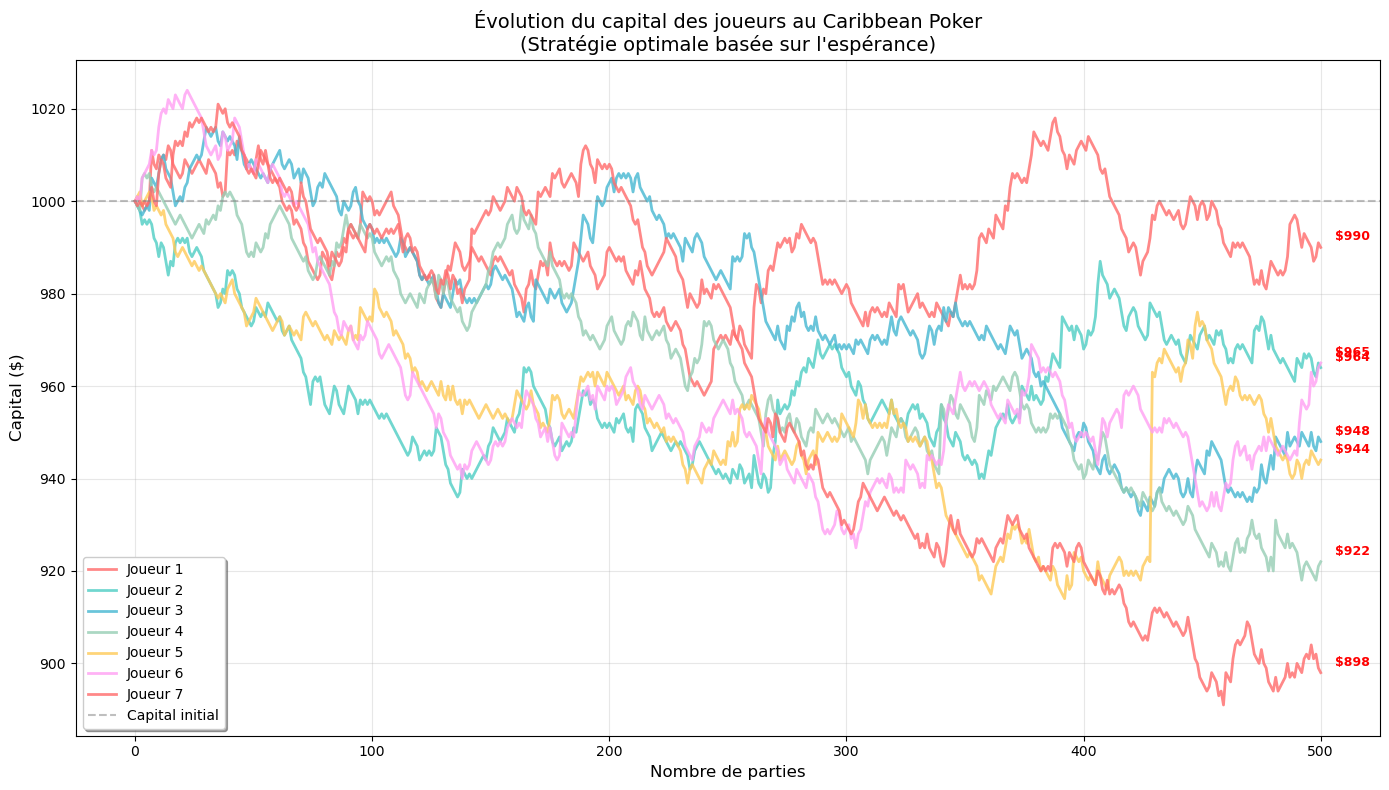


📊 STATISTIQUES FINALES

Joueur 1:
  💰 Capital final: $990.00
  💸 Profit/Perte: $-10.00 (-1.0%)
  📊 Décisions: 259 calls, 241 folds
  🏆 Résultats: 84 victoires, 66 défaites
  🚫 Dealer non qualifié: 109 fois

Joueur 2:
  💰 Capital final: $964.00
  💸 Profit/Perte: $-36.00 (-3.6%)
  📊 Décisions: 265 calls, 235 folds
  🏆 Résultats: 77 victoires, 71 défaites
  🚫 Dealer non qualifié: 117 fois

Joueur 3:
  💰 Capital final: $948.00
  💸 Profit/Perte: $-52.00 (-5.2%)
  📊 Décisions: 259 calls, 241 folds
  🏆 Résultats: 77 victoires, 67 défaites
  🚫 Dealer non qualifié: 115 fois

Joueur 4:
  💰 Capital final: $922.00
  💸 Profit/Perte: $-78.00 (-7.8%)
  📊 Décisions: 259 calls, 241 folds
  🏆 Résultats: 70 victoires, 70 défaites
  🚫 Dealer non qualifié: 119 fois

Joueur 5:
  💰 Capital final: $944.00
  💸 Profit/Perte: $-56.00 (-5.6%)
  📊 Décisions: 255 calls, 245 folds
  🏆 Résultats: 64 victoires, 68 défaites
  🚫 Dealer non qualifié: 123 fois

Joueur 6:
  💰 Capital final: $965.00
  💸 Profit/Perte: $-35.

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# ===== CONFIGURATION DE LA SIMULATION =====
NUM_PLAYERS = 7          # Nombre de joueurs
INITIAL_CAPITAL = 1000    # Capital initial de chaque joueur ($)
ANTE_BET = 1             # Mise ante ($)
CALL_BET = 2             # Mise call ($)  
NUM_ROUNDS = 500        # Nombre de parties à simuler
SEED = 100                # Seed pour reproductibilité
# ==========================================

from helpers import caribbean as cb

def simulate_caribbean_poker_game(num_players=NUM_PLAYERS, initial_capital=INITIAL_CAPITAL,
                                 num_rounds=NUM_ROUNDS, ante_bet=ANTE_BET, call_bet=CALL_BET,
                                 seed=SEED, info="own"):
    """
    Simule plusieurs parties de Caribbean Poker avec des joueurs suivant la stratégie
    optimale (CALL si EV(call) > -ante), calculée exactement dans helpers/caribbean.py.

    Corrections par rapport à la première version :
    - un seul jeu mélangé et UNE SEULE main du dealer par partie, partagée par tous
      les joueurs (avant : chaque joueur tirait sa propre main du dealer) ;
    - info="own" : le joueur ne connaît que sa main et la carte visible du dealer
      (casino réel, C(46,4) = 163 185 mains possibles du dealer). info="table" :
      il voit aussi les mains des autres joueurs (avant : toujours le cas) ;
    - gains corrects : dealer non qualifié +ante, victoire +ante + call × multiplicateur.

    Returns:
        dict: Historique des capitaux et statistiques
    """
    res = cb.simulate_table(num_players, num_rounds, info, seed, ante_bet, call_bet)
    pnl, called = res["pnl"], res["called"]
    player_capitals, stats = {}, {}
    for i in range(num_players):
        name = f"Joueur {i+1}"
        player_capitals[name] = list(initial_capital + np.concatenate([[0], np.cumsum(pnl[:, i])]))
        c = called[:, i]
        stats[name] = {
            'calls': int(c.sum()),
            'folds': int((~c).sum()),
            'wins': int((c & (pnl[:, i] > ante_bet)).sum()),
            'losses': int((c & (pnl[:, i] < 0)).sum()),
            'non_qualified': int((c & (pnl[:, i] == ante_bet)).sum()),
        }
    return player_capitals, stats

def plot_capital_evolution(player_capitals, stats, initial_capital=INITIAL_CAPITAL):
    """
    Affiche l'évolution du capital de chaque joueur au fil du temps.
    """
    plt.figure(figsize=(14, 8))
    
    # Couleurs pour chaque joueur
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FECA57', '#FF9FF3']
    
    # Tracer les courbes
    for i, (player, capitals) in enumerate(player_capitals.items()):
        plt.plot(capitals, label=player, color=colors[i % len(colors)], linewidth=2, alpha=0.8)
    
    # Ligne de référence au capital initial
    plt.axhline(y=initial_capital, color='gray', linestyle='--', alpha=0.5, label='Capital initial')
    
    # Personnalisation du graphique
    plt.xlabel('Nombre de parties', fontsize=12)
    plt.ylabel('Capital ($)', fontsize=12)
    plt.title('Évolution du capital des joueurs au Caribbean Poker\n(Stratégie optimale basée sur l\'espérance)', fontsize=14)
    plt.legend(loc='best', frameon=True, fancybox=True, shadow=True)
    plt.grid(True, alpha=0.3)
    
    # Ajouter des annotations pour les capitaux finaux
    for i, (player, capitals) in enumerate(player_capitals.items()):
        final_capital = capitals[-1]
        profit = final_capital - initial_capital
        color = 'green' if profit > 0 else 'red'
        plt.annotate(f'${final_capital:.0f}', 
                    xy=(len(capitals)-1, final_capital),
                    xytext=(10, 5),
                    textcoords='offset points',
                    fontsize=9,
                    color=color,
                    weight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # Afficher les statistiques
    print("\n📊 STATISTIQUES FINALES")
    print("="*60)
    
    for player, capitals in player_capitals.items():
        final_capital = capitals[-1]
        profit = final_capital - initial_capital
        profit_pct = (profit / initial_capital) * 100
        
        print(f"\n{player}:")
        print(f"  💰 Capital final: ${final_capital:.2f}")
        print(f"  💸 Profit/Perte: ${profit:+.2f} ({profit_pct:+.1f}%)")
        print(f"  📊 Décisions: {stats[player]['calls']} calls, {stats[player]['folds']} folds")
        print(f"  🏆 Résultats: {stats[player]['wins']} victoires, {stats[player]['losses']} défaites")
        print(f"  🚫 Dealer non qualifié: {stats[player]['non_qualified']} fois")

# Lancer la simulation
print("🎰 SIMULATION DE CARIBBEAN POKER")
print("="*60)
print(f"Configuration:")
print(f"  • {NUM_PLAYERS} joueurs")
print(f"  • Capital initial: ${INITIAL_CAPITAL} chacun")
print(f"  • {NUM_ROUNDS} parties")
print(f"  • Mise ante: ${ANTE_BET}")
print(f"  • Mise call: ${CALL_BET}")
print(f"  • Mise totale max: ${ANTE_BET + CALL_BET}")
print(f"  • Stratégie: Maximisation de l'espérance (EV)")
print(f"  • Information utilisée: Main propre + carte visible du dealer (casino réel)")
print("="*60)


# Lancer la simulation
player_capitals, stats = simulate_caribbean_poker_game()

# Afficher le graphique
plot_capital_evolution(player_capitals, stats)

## 9. Monte Carlo (code vérifié, voir tests/test_caribbean.py)


DÉMARRAGE DE L'ANALYSE MONTE CARLO
🎲 SIMULATION MONTE CARLO
Configuration:
  • 10 simulations indépendantes
  • 500 parties par simulation
  • 7 joueurs par simulation
  • Capital initial: $1000
  • Niveau de confiance: 95.0%
Progression: 10/10 simulations (100.0%)

⏱️ Temps d'exécution: 314.61 secondes

📊 STATISTIQUES MONTE CARLO

🎯 Joueur 1:
  💰 Profit moyen: $-43.60 (-4.4%)
  📊 Écart-type: $34.19
  📈 Intervalle de confiance 95.0%: [$-69.38, $-17.82]
  📉 Min/Max: $-100.00 / $+2.00
  🎲 Probabilités:
    • Profit: 10.0%
    • Perte: 90.0%
    • Break-even: 0.0%
  🏆 Taux de victoire: 30.0% ± 1.9%
  🚫 Dealer non qualifié: 43.3% ± 2.1%
  ⚠️ Risque (VaR):
    • VaR 95%: $-91.00
    • VaR 99%: $-98.20

🎯 Joueur 2:
  💰 Profit moyen: $-26.00 (-2.6%)
  📊 Écart-type: $40.88
  📈 Intervalle de confiance 95.0%: [$-56.83, $+4.83]
  📉 Min/Max: $-100.00 / $+40.00
  🎲 Probabilités:
    • Profit: 20.0%
    • Perte: 80.0%
    • Break-even: 0.0%
  🏆 Taux de victoire: 30.2% ± 2.4%
  🚫 Dealer non qualifié

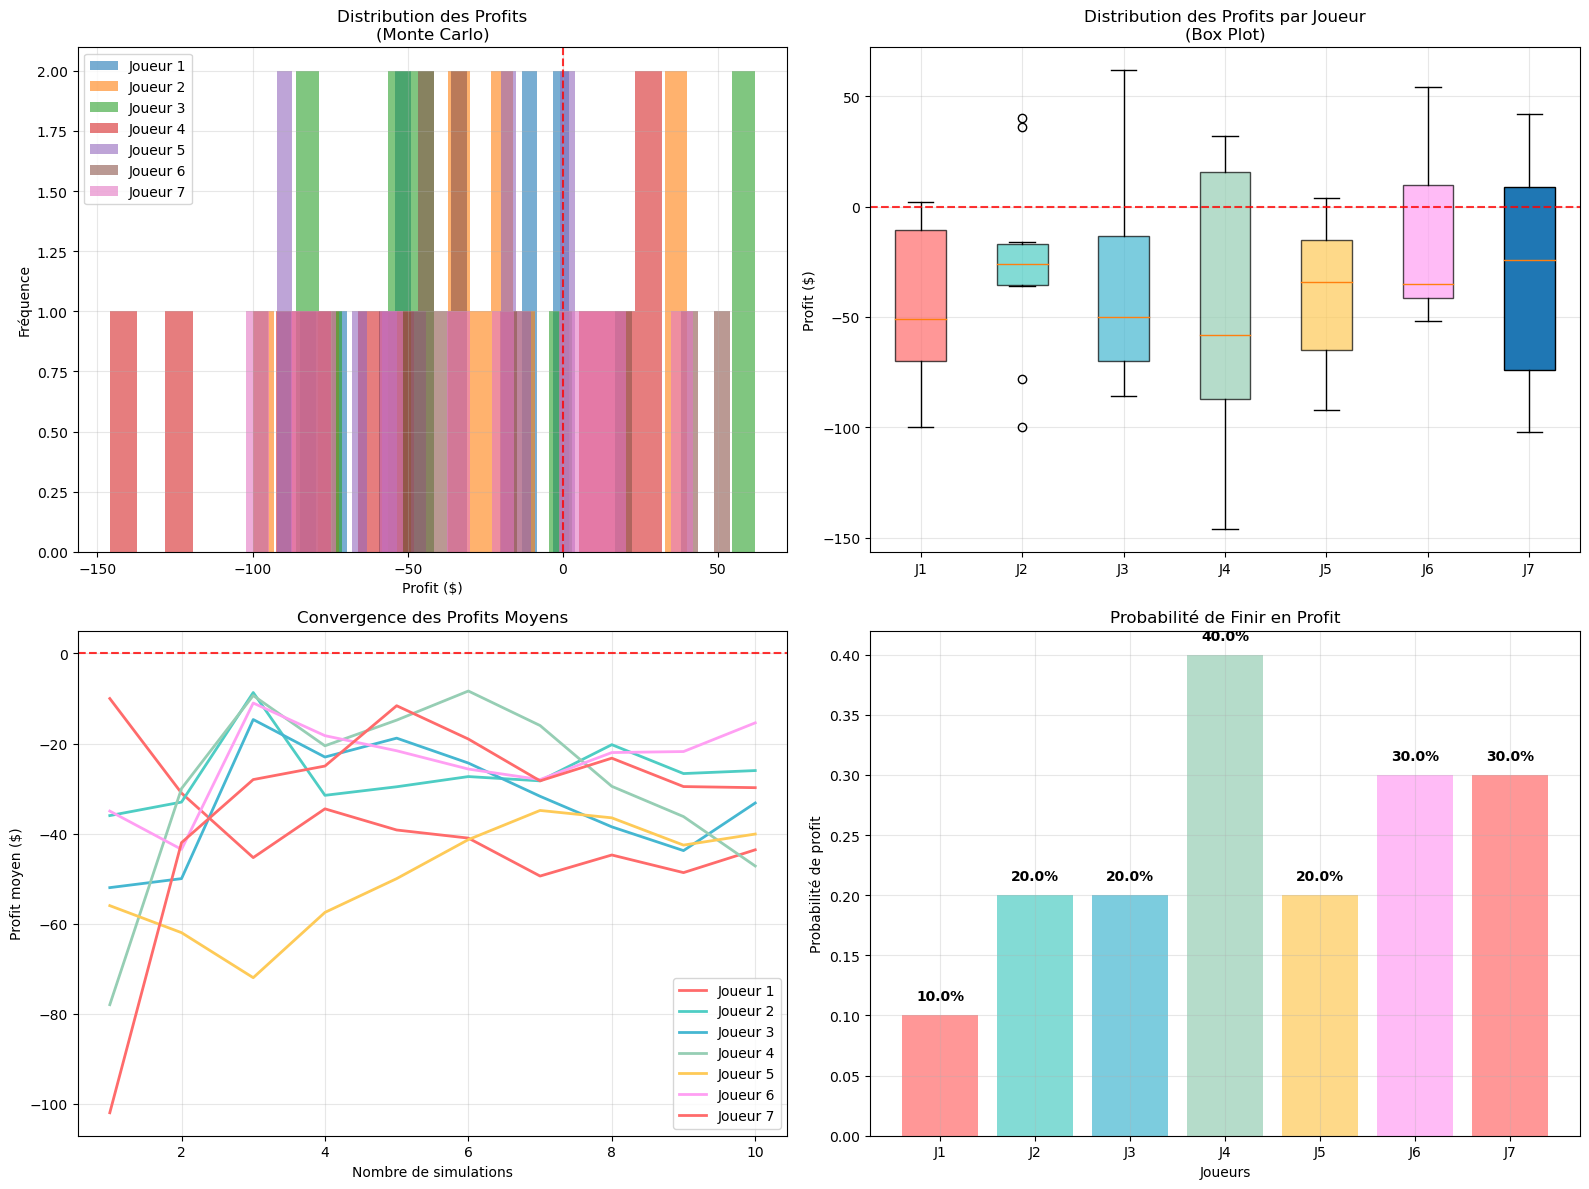


🎯 CONCLUSION MONTE CARLO
L'analyse Monte Carlo révèle la distribution statistique des résultats
et permet d'évaluer le risque et la variabilité de la stratégie optimale.
Les intervalles de confiance indiquent la précision des estimations.


In [12]:
import scipy.stats as stats
from concurrent.futures import ProcessPoolExecutor
import time

# ===== CONFIGURATION MONTE CARLO =====
MC_NUM_SIMULATIONS = 10        # Nombre de simulations Monte Carlo
MC_ROUNDS_PER_SIM = 500         # Nombre de parties par simulation
MC_CONFIDENCE_LEVEL = 0.95      # Niveau de confiance pour intervalles
# ====================================

def run_single_simulation(sim_id):
    """
    Exécute une seule simulation Caribbean Poker.
    
    Args:
        sim_id (int): Identifiant de la simulation
    
    Returns:
        dict: Résultats de la simulation
    """
    # Seed différente pour chaque simulation
 
    # Lancer la simulation
    player_capitals, stats = simulate_caribbean_poker_game(
        num_players=NUM_PLAYERS,
        initial_capital=INITIAL_CAPITAL,
        num_rounds=MC_ROUNDS_PER_SIM,
        ante_bet=ANTE_BET,
        call_bet=CALL_BET,
        seed=SEED + sim_id
    )
    
    # Extraire les résultats finaux
    results = {
        'simulation_id': sim_id,
        'final_capitals': {},
        'profits': {},
        'profit_percentages': {},
        'total_calls': {},
        'total_folds': {},
        'win_rates': {},
        'non_qualified_rates': {}
    }
    
    for player in player_capitals.keys():
        final_capital = player_capitals[player][-1]
        profit = final_capital - INITIAL_CAPITAL
        profit_pct = (profit / INITIAL_CAPITAL) * 100
        
        total_games = stats[player]['calls'] + stats[player]['folds']
        win_rate = stats[player]['wins'] / stats[player]['calls'] if stats[player]['calls'] > 0 else 0
        non_qualified_rate = stats[player]['non_qualified'] / stats[player]['calls'] if stats[player]['calls'] > 0 else 0
        
        results['final_capitals'][player] = final_capital
        results['profits'][player] = profit
        results['profit_percentages'][player] = profit_pct
        results['total_calls'][player] = stats[player]['calls']
        results['total_folds'][player] = stats[player]['folds']
        results['win_rates'][player] = win_rate
        results['non_qualified_rates'][player] = non_qualified_rate
    
    return results

def monte_carlo_analysis():
    """
    Effectue une analyse Monte Carlo complète du Caribbean Poker.
    
    Returns:
        dict: Résultats statistiques complets
    """
    print("🎲 SIMULATION MONTE CARLO")
    print("="*60)
    print(f"Configuration:")
    print(f"  • {MC_NUM_SIMULATIONS} simulations indépendantes")
    print(f"  • {MC_ROUNDS_PER_SIM} parties par simulation")
    print(f"  • {NUM_PLAYERS} joueurs par simulation")
    print(f"  • Capital initial: ${INITIAL_CAPITAL}")
    print(f"  • Niveau de confiance: {MC_CONFIDENCE_LEVEL*100}%")
    print("="*60)
    
    start_time = time.time()
    
    # Exécution des simulations (séquentielle pour éviter les problèmes de concurrence)
    all_results = []
    for i in range(MC_NUM_SIMULATIONS):
        if (i + 1) % 10 == 0:
            print(f"Progression: {i + 1}/{MC_NUM_SIMULATIONS} simulations ({(i+1)/MC_NUM_SIMULATIONS*100:.1f}%)")
        results = run_single_simulation(i)
        all_results.append(results)
    
    end_time = time.time()
    print(f"\n⏱️ Temps d'exécution: {end_time - start_time:.2f} secondes")
    
    # Analyse statistique
    player_names = [f"Joueur {i+1}" for i in range(NUM_PLAYERS)]
    
    # Collecter toutes les données
    all_profits = {player: [] for player in player_names}
    all_profit_pcts = {player: [] for player in player_names}
    all_win_rates = {player: [] for player in player_names}
    all_non_qualified_rates = {player: [] for player in player_names}
    
    for result in all_results:
        for player in player_names:
            all_profits[player].append(result['profits'][player])
            all_profit_pcts[player].append(result['profit_percentages'][player])
            all_win_rates[player].append(result['win_rates'][player])
            all_non_qualified_rates[player].append(result['non_qualified_rates'][player])
    
    # Calculs statistiques
    mc_stats = {}
    
    for player in player_names:
        profits = np.array(all_profits[player])
        profit_pcts = np.array(all_profit_pcts[player])
        win_rates = np.array(all_win_rates[player])
        non_qual_rates = np.array(all_non_qualified_rates[player])
        
        # Intervalles de confiance
        alpha = 1 - MC_CONFIDENCE_LEVEL
        profit_ci = stats.t.interval(MC_CONFIDENCE_LEVEL, len(profits)-1, 
                                   loc=np.mean(profits), scale=stats.sem(profits))
        win_rate_ci = stats.t.interval(MC_CONFIDENCE_LEVEL, len(win_rates)-1,
                                     loc=np.mean(win_rates), scale=stats.sem(win_rates))
        
        mc_stats[player] = {
            # Profits
            'profit_mean': np.mean(profits),
            'profit_std': np.std(profits),
            'profit_min': np.min(profits),
            'profit_max': np.max(profits),
            'profit_ci': profit_ci,
            'profit_pct_mean': np.mean(profit_pcts),
            
            # Probabilité de profit
            'prob_profit': np.mean(profits > 0),
            'prob_loss': np.mean(profits < 0),
            'prob_breakeven': np.mean(profits == 0),
            
            # Taux de victoire
            'win_rate_mean': np.mean(win_rates),
            'win_rate_std': np.std(win_rates),
            'win_rate_ci': win_rate_ci,
            
            # Taux dealer non qualifié
            'non_qualified_mean': np.mean(non_qual_rates),
            'non_qualified_std': np.std(non_qual_rates),
            
            # Risque (VaR)
            'var_95': np.percentile(profits, 5),  # Value at Risk 95%
            'var_99': np.percentile(profits, 1),  # Value at Risk 99%
        }
    
    return mc_stats, all_results

def plot_monte_carlo_results(mc_stats, all_results):
    """
    Crée des graphiques pour l'analyse Monte Carlo.
    """
    player_names = list(mc_stats.keys())
    
    # Figure avec sous-graphiques
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. Distribution des profits
    ax1 = axes[0, 0]
    for i, player in enumerate(player_names):
        profits = [result['profits'][player] for result in all_results]
        ax1.hist(profits, alpha=0.6, label=player, bins=20)
    ax1.set_xlabel('Profit ($)')
    ax1.set_ylabel('Fréquence')
    ax1.set_title('Distribution des Profits\n(Monte Carlo)')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.axvline(x=0, color='red', linestyle='--', alpha=0.8, label='Seuil de rentabilité')
    
    # 2. Box plot des profits
    ax2 = axes[0, 1]
    profits_data = [[result['profits'][player] for result in all_results] for player in player_names]
    bp = ax2.boxplot(profits_data, labels=[f"J{i+1}" for i in range(len(player_names))], patch_artist=True)
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FECA57', '#FF9FF3']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax2.set_ylabel('Profit ($)')
    ax2.set_title('Distribution des Profits par Joueur\n(Box Plot)')
    ax2.grid(True, alpha=0.3)
    ax2.axhline(y=0, color='red', linestyle='--', alpha=0.8)
    
    # 3. Évolution des profits moyens
    ax3 = axes[1, 0]
    for i, player in enumerate(player_names):
        profit_means = []
        for n in range(1, MC_NUM_SIMULATIONS + 1):
            profits_subset = [all_results[j]['profits'][player] for j in range(n)]
            profit_means.append(np.mean(profits_subset))
        ax3.plot(range(1, MC_NUM_SIMULATIONS + 1), profit_means, 
                label=player, color=colors[i % len(colors)], linewidth=2)
    ax3.set_xlabel('Nombre de simulations')
    ax3.set_ylabel('Profit moyen ($)')
    ax3.set_title('Convergence des Profits Moyens')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.axhline(y=0, color='red', linestyle='--', alpha=0.8)
    
    # 4. Probabilités de profit
    ax4 = axes[1, 1]
    prob_profits = [mc_stats[player]['prob_profit'] for player in player_names]
    bars = ax4.bar(range(len(player_names)), prob_profits, 
                   color=colors[:len(player_names)], alpha=0.7)
    ax4.set_xlabel('Joueurs')
    ax4.set_ylabel('Probabilité de profit')
    ax4.set_title('Probabilité de Finir en Profit')
    ax4.set_xticks(range(len(player_names)))
    ax4.set_xticklabels([f"J{i+1}" for i in range(len(player_names))])
    ax4.grid(True, alpha=0.3)
    
    # Ajouter les valeurs sur les barres
    for i, (bar, prob) in enumerate(zip(bars, prob_profits)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{prob:.1%}', ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.show()

def print_monte_carlo_stats(mc_stats):
    """
    Affiche les statistiques Monte Carlo.
    """
    print("\n📊 STATISTIQUES MONTE CARLO")
    print("="*80)
    
    for player, stats_data in mc_stats.items():
        print(f"\n🎯 {player}:")
        print(f"  💰 Profit moyen: ${stats_data['profit_mean']:+.2f} ({stats_data['profit_pct_mean']:+.1f}%)")
        print(f"  📊 Écart-type: ${stats_data['profit_std']:.2f}")
        print(f"  📈 Intervalle de confiance {MC_CONFIDENCE_LEVEL*100}%: [${stats_data['profit_ci'][0]:+.2f}, ${stats_data['profit_ci'][1]:+.2f}]")
        print(f"  📉 Min/Max: ${stats_data['profit_min']:+.2f} / ${stats_data['profit_max']:+.2f}")
        
        print(f"  🎲 Probabilités:")
        print(f"    • Profit: {stats_data['prob_profit']:.1%}")
        print(f"    • Perte: {stats_data['prob_loss']:.1%}")
        print(f"    • Break-even: {stats_data['prob_breakeven']:.1%}")
        
        print(f"  🏆 Taux de victoire: {stats_data['win_rate_mean']:.1%} ± {stats_data['win_rate_std']:.1%}")
        print(f"  🚫 Dealer non qualifié: {stats_data['non_qualified_mean']:.1%} ± {stats_data['non_qualified_std']:.1%}")
        
        print(f"  ⚠️ Risque (VaR):")
        print(f"    • VaR 95%: ${stats_data['var_95']:+.2f}")
        print(f"    • VaR 99%: ${stats_data['var_99']:+.2f}")
    
    # Statistiques globales
    print("\n🌍 STATISTIQUES GLOBALES:")
    all_profit_means = [stats_data['profit_mean'] for stats_data in mc_stats.values()]
    print(f"  💰 Profit moyen global: ${np.mean(all_profit_means):+.2f}")
    print(f"  📊 Écart-type global: ${np.std(all_profit_means):.2f}")
    
    best_player = max(mc_stats.keys(), key=lambda p: mc_stats[p]['profit_mean'])
    worst_player = min(mc_stats.keys(), key=lambda p: mc_stats[p]['profit_mean'])
    print(f"  🥇 Meilleur joueur: {best_player} (${mc_stats[best_player]['profit_mean']:+.2f})")
    print(f"  🥉 Moins bon joueur: {worst_player} (${mc_stats[worst_player]['profit_mean']:+.2f})")

# Exécution de l'analyse Monte Carlo
print("\n" + "="*80)
print("DÉMARRAGE DE L'ANALYSE MONTE CARLO")
print("="*80)

mc_stats, all_results = monte_carlo_analysis()
print_monte_carlo_stats(mc_stats)
plot_monte_carlo_results(mc_stats, all_results)

print("\n" + "="*80)
print("🎯 CONCLUSION MONTE CARLO")
print("="*80)
print("L'analyse Monte Carlo révèle la distribution statistique des résultats")
print("et permet d'évaluer le risque et la variabilité de la stratégie optimale.")
print("Les intervalles de confiance indiquent la précision des estimations.")

## 10. Validation : avantage de la maison

`run_experiments.py` rejoue la stratégie optimale sur 20 000 parties à 7 joueurs (140 000 mains) et écrit `results/results.json`. Deux estimateurs sur les mêmes donnes : le P&L réalisé (forte variance) et l'EV exacte de l'action choisie (même moyenne, variance bien plus faible), avec un intervalle de confiance groupé par partie (tous les joueurs affrontent la même main du dealer). Référence publiée : avantage maison de 5,224 % de l'ante, CALL dans ~52,2 % des mains.

In [13]:
import json
r = json.load(open('results/results.json'))
for info, label in [('own', 'Main propre seulement (casino)'), ('table', 'Toute la table visible')]:
    ev, real = r[info]['exact_ev'], r[info]['realized']
    print(f"{label}: avantage maison {ev['house_edge_pct_of_ante']:.2f} % de l'ante "
          f"(IC 95 % de l'EV par main [{ev['ci'][0]:.4f}, {ev['ci'][1]:.4f}]), "
          f"P&L réalisé {real['mean_per_hand']:+.4f} ± {1.96*real['se']:.4f}, taux de CALL {r[info]['call_rate']:.1%}")
v = r['value_of_table_information']
print(f"Valeur de l'information de table : {v['mean_per_hand']:+.4f} par main (IC 95 % [{v['ci'][0]:.4f}, {v['ci'][1]:.4f}])")
print('Référence publiée : 5,224 % de l\'ante, CALL ~52,2 %')


Main propre seulement (casino): avantage maison 5.63 % de l'ante (IC 95 % de l'EV par main [-0.0643, -0.0484]), P&L réalisé -0.0478 ± 0.0153, taux de CALL 52.1%
Toute la table visible: avantage maison -2.30 % de l'ante (IC 95 % de l'EV par main [0.0147, 0.0314]), P&L réalisé +0.0248 ± 0.0170, taux de CALL 62.9%
Valeur de l'information de table : +0.0794 par main (IC 95 % [0.0760, 0.0827])
Référence publiée : 5,224 % de l'ante, CALL ~52,2 %
